### CRISP-DM · Fase 2: Comprensión de los datos

Carga de los datos, partición y exploración del grupo de entrenamiento.

- **Entrada:** `data/raw/penguins_size.csv`
- **Salidas:**
  - `crisp_dm/data/interim/train.csv`, `crisp_dm/data/interim/test.csv`: grupos de entrenamiento y prueba
  - `crisp_dm/data/interim/split_summary.csv`: resumen de la partición
  - `crisp_dm/data/interim/data_quality.csv`: resumen de calidad por variable
  - `crisp_dm/figures/understanding_*.png`: figuras de la exploración
- **Variable objetivo:** `species`

#### Librerías

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
RAW_PATH = Path("../../data/raw/penguins_size.csv")
INTERIM_DIR = Path("../data/interim")
FIGURES_DIR = Path("../figures")
for folder in [INTERIM_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [4]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [5]:
df = pd.read_csv(RAW_PATH)

print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")
df.head()

Registros: 344 | Variables: 7


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


#### Tipos de datos y valores faltantes

In [6]:
pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "faltantes": df.isna().sum(),
    "valores_distintos": df.nunique(),
})

,tipo,no_nulos,faltantes,valores_distintos
species,object,344,0,3
island,object,344,0,3
culmen_length_mm,float64,342,2,164
culmen_depth_mm,float64,342,2,80
flipper_length_mm,float64,342,2,55
body_mass_g,float64,342,2,94
sex,object,334,10,3


#### Distribución de la variable objetivo

In [7]:
pd.DataFrame({
    "registros": df["species"].value_counts(),
    "proporcion": df["species"].value_counts(normalize=True).round(3),
})

,registros,proporcion
species,,
Adelie,152,0.442
Gentoo,124,0.360
Chinstrap,68,0.198


#### Identificador de registro

`row_id` guarda la posición original de cada fila. No se usa como variable predictora.

In [8]:
df = df.reset_index().rename(columns={"index": "row_id"})

#### Partición 80/20 estratificada por `species`

La exploración usa solo el grupo de entrenamiento.

In [9]:
TARGET = "species"
NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]
FEATURES = NUMERIC + CATEGORICAL
TEST_SIZE = 0.20

train, test = train_test_split(df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=SEED)

split_summary = pd.DataFrame({
    "total_n": df[TARGET].value_counts(),
    "train_n": train[TARGET].value_counts(),
    "test_n": test[TARGET].value_counts(),
    "total_prop": df[TARGET].value_counts(normalize=True),
    "train_prop": train[TARGET].value_counts(normalize=True),
    "test_prop": test[TARGET].value_counts(normalize=True),
}).round(3)
split_summary.index.name = TARGET
split_summary

,total_n,train_n,test_n,total_prop,train_prop,test_prop
species,,,,,,
Adelie,152,122,30,0.442,0.444,0.435
Gentoo,124,99,25,0.360,0.360,0.362
Chinstrap,68,54,14,0.198,0.196,0.203


#### Estadística descriptiva por especie

In [10]:
train.groupby(TARGET)[NUMERIC].agg(["mean", "std", "min", "max"]).round(2).T

species                  Adelie  Chinstrap   Gentoo
culmen_length_mm  mean    38.71      48.73    47.39
                  std      2.71       3.29     3.04
                  min     32.10      40.90    40.90
                  max     46.00      58.00    59.60
culmen_depth_mm   mean    18.32      18.51    14.96
                  std      1.23       1.11     0.99
                  min     15.50      16.40    13.20
                  max     21.50      20.80    17.30
flipper_length_mm mean   189.50     195.78   216.81
                  std      6.44       7.40     6.46
                  min    172.00     178.00   203.00
                  max    208.00     212.00   231.00
body_mass_g       mean  3676.24    3713.89  5081.63
                  std    453.43     383.31   510.04
                  min   2850.00    2700.00  3950.00
                  max   4775.00    4800.00  6300.00

#### Valores de las variables categóricas

In [11]:
for col in CATEGORICAL:
    print(f"--- {col} ---")
    print(train[col].value_counts(dropna=False).to_string(), "\n")

--- island ---
island
Biscoe       133
Dream        101
Torgersen     41 

--- sex ---
sex
FEMALE    134
MALE      133
NaN         8 



#### Especie por isla

In [12]:
pd.crosstab(train[TARGET], train["island"], margins=True, margins_name="Total")

island,Biscoe,Dream,Torgersen,Total
species,,,,
Adelie,34,47,41,122
Chinstrap,0,54,0,54
Gentoo,99,0,0,99
Total,133,101,41,275


#### Distribución de las variables numéricas por especie

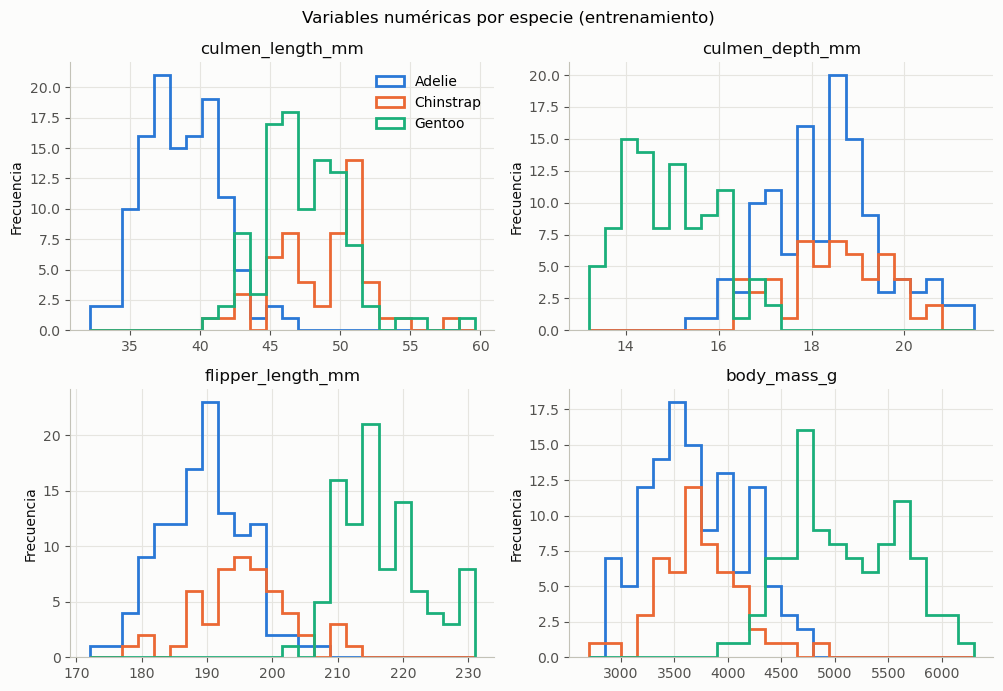

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.flat, NUMERIC):
    values = train[col].dropna()
    bins = np.linspace(values.min(), values.max(), 25)
    for sp in SPECIES:
        ax.hist(train.loc[train[TARGET] == sp, col].dropna(), bins=bins,
                histtype="step", linewidth=2, color=COLORS[sp], label=sp)
    ax.set_title(col)
    ax.set_ylabel("Frecuencia")

axes[0, 0].legend()
fig.suptitle("Variables numéricas por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "understanding_histograms.png")
plt.show()

#### Relación entre pares de variables

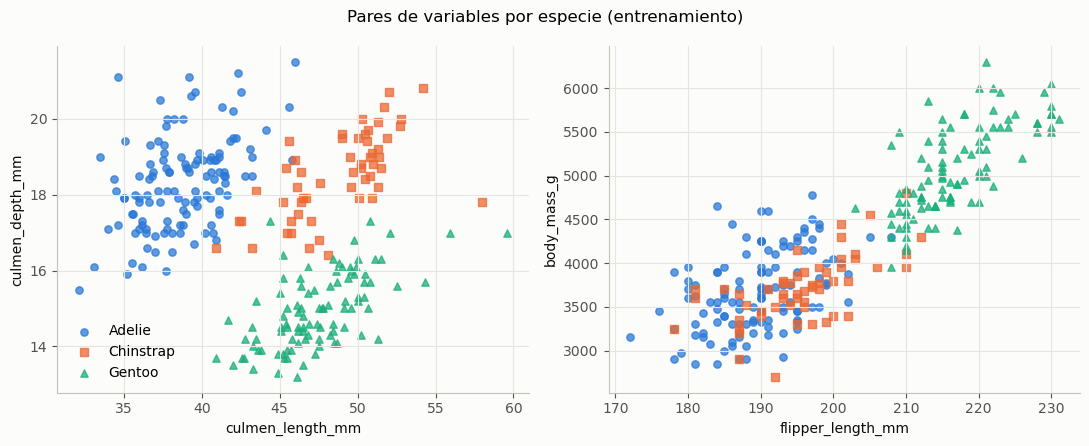

In [14]:
pairs = [
    ("culmen_length_mm", "culmen_depth_mm"),
    ("flipper_length_mm", "body_mass_g"),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (x, y) in zip(axes, pairs):
    for sp in SPECIES:
        sub = train[train[TARGET] == sp]
        ax.scatter(sub[x], sub[y], s=28, alpha=0.75, color=COLORS[sp], marker=MARKERS[sp], label=sp)
    ax.set_xlabel(x)
    ax.set_ylabel(y)

axes[0].legend()
fig.suptitle("Pares de variables por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "understanding_scatter.png")
plt.show()

#### Correlación entre variables numéricas

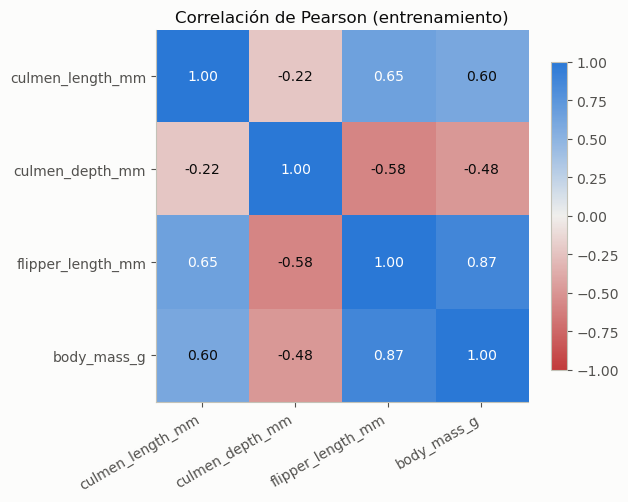

In [15]:
corr = train[NUMERIC].corr().round(2)
cmap = LinearSegmentedColormap.from_list("div", ["#c23b3b", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="#ffffff" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=30, ha="right")
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
ax.grid(False)
ax.set_title("Correlación de Pearson (entrenamiento)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGURES_DIR / "understanding_correlation.png")
plt.show()

#### Resumen de calidad por variable

In [16]:
data_quality = pd.DataFrame({
    "tipo": train[FEATURES + [TARGET]].dtypes.astype(str),
    "faltantes": train[FEATURES + [TARGET]].isna().sum(),
    "valores_distintos": train[FEATURES + [TARGET]].nunique(),
})
data_quality["valores_no_validos"] = 0
data_quality.loc["sex", "valores_no_validos"] = int((~train["sex"].isin(["MALE", "FEMALE"]) & train["sex"].notna()).sum())
data_quality

,tipo,faltantes,valores_distintos,valores_no_validos
culmen_length_mm,float64,2,146,0
culmen_depth_mm,float64,2,76,0
flipper_length_mm,float64,2,53,0
body_mass_g,float64,2,89,0
island,object,0,3,0
sex,object,8,2,0
species,object,0,3,0


#### Guardado de resultados

In [17]:
train.to_csv(INTERIM_DIR / "train.csv", index=False)
test.to_csv(INTERIM_DIR / "test.csv", index=False)
split_summary.to_csv(INTERIM_DIR / "split_summary.csv")
data_quality.to_csv(INTERIM_DIR / "data_quality.csv")

for path in ["train.csv", "test.csv", "split_summary.csv", "data_quality.csv"]:
    print(f"Guardado: {INTERIM_DIR / path}")

Guardado: ..\data\interim\train.csv
Guardado: ..\data\interim\test.csv
Guardado: ..\data\interim\split_summary.csv
Guardado: ..\data\interim\data_quality.csv
